author - ransell

# Bradley–Terry Humanness Scores


In [1]:
!pip install statsmodels numpy seaborn matplotlib

**Bradley-Terry Rankings for X and YT pairs**

At this point -> the more positive the normalized ranking between -1 and 1, the more AI like the post. 

In [2]:
import pandas as pd
import numpy as np
import statsmodels.api as sm

def run_bt_analysis(file_path, output_csv):
    data = pd.read_csv(file_path)
    data = data[data['post_winner'] != data['post_loser']].reset_index(drop=True)
    
    pairs = pd.DataFrame({'winner': data['post_winner'], 'loser': data['post_loser']})
    winners = pairs['winner'].dropna().astype(str).unique()
    losers  = pairs['loser'].dropna().astype(str).unique()
    teams = pd.Series(np.union1d(winners, losers))

    pairs['winner_code'] = pd.Categorical(pairs['winner'].astype(str), categories=teams).codes
    pairs['loser_code']  = pd.Categorical(pairs['loser'].astype(str), categories=teams).codes

    X = np.zeros((len(pairs), len(teams)))
    X[np.arange(len(pairs)), pairs['winner_code']] = 1
    X[np.arange(len(pairs)), pairs['loser_code']]  = -1
    y = np.ones(len(pairs))

    model = sm.GLM(y, X[:, 1:], family=sm.families.Binomial())
    results = model.fit()

    abilities = np.concatenate(([0], results.params))
    norm = -1 + 2 * (np.argsort(np.argsort(abilities)) / (len(abilities) - 1))

    rankings = []
    for i, post in enumerate(teams):
        if post in data['post_winner'].astype(str).values:
            text_id = data[data['post_winner'].astype(str) == post].iloc[0]['id_winner']
        else:
            text_id = data[data['post_loser'].astype(str) == post].iloc[0]['id_loser']
        rankings.append({'Text': post, 'Text_ID': int(text_id), 'Ability': abilities[i], 'Normalized Ability': norm[i]})
    
    pd.DataFrame(rankings).to_csv(output_csv, index=False)
    print(f"Saved: {output_csv}")

# Run for both platforms
run_bt_analysis("data/x_data.csv",  "data/bt_x_posts_rankings.csv")
run_bt_analysis("data/yt_data.csv", "data/bt_yt_posts_rankings.csv")


Saved: data/bt_x_posts_rankings.csv
Saved: data/bt_yt_posts_rankings.csv


Merging in metadata from selected_posts

In [5]:
import pandas as pd
import numpy as np

def merge_bt_with_model_and_persona(
    bt_path,           
    posts_path,        # Path to model + human post metadata CSV
    post_text_col,     
    output_path,       
    label             
):
    print(f"\n--- Merging for {label} ---")

    # Load data
    bt_df = pd.read_csv(bt_path)
    posts_df = pd.read_csv(posts_path)

    # Normalize text
    bt_df['Text'] = bt_df['Text'].astype(str).str.strip()
    posts_df[post_text_col] = posts_df[post_text_col].astype(str).str.strip()

    # Separate AI and human posts
    ai_df = posts_df[posts_df['source'].str.lower() != 'human']
    human_df = posts_df[posts_df['source'].str.lower() == 'human']

    # Drop duplicate posts to prevent merge explosion
    ai_df = ai_df.drop_duplicates(subset=post_text_col, keep='first')
    human_df = human_df.drop_duplicates(subset=post_text_col, keep='first')

    # Merge AI metadata (source, persona) by post text
    merged = pd.merge(
        bt_df,
        ai_df[[post_text_col, 'source', 'persona']],
        left_on='Text',
        right_on=post_text_col,
        how='left'
    ).drop(columns=[post_text_col], errors='ignore')

    # Derive model column: if no AI source matched, it's human
    merged['model'] = merged['source'].apply(
        lambda x: str(x).strip().lower() if pd.notna(x) else 'human'
    )

    # Set persona to NaN for human posts
    merged['persona'] = merged.apply(
        lambda row: row['persona'] if row['model'] != 'human' else np.nan,
        axis=1
    )

    # Drop duplicates just in case
    merged = merged.drop_duplicates()

    # Save
    merged.to_csv(output_path, index=False)
    print(f"Saved to {output_path} ({len(merged)} records)")

# Run for both platforms
merge_bt_with_model_and_persona(
    bt_path='data/bt_x_posts_rankings.csv',
    posts_path='data/x_posts_with_model_combined_clean.csv',
    post_text_col='post',
    output_path='data/bt_x_posts_rankings_with_source_persona.csv',
    label='X Platform'
)

merge_bt_with_model_and_persona(
    bt_path='data/bt_yt_posts_rankings.csv',
    posts_path='data/yt_all_generated_posts_clean.csv',
    post_text_col='generated_post',
    output_path='data/bt_yt_posts_rankings_with_source_persona.csv',
    label='YouTube Platform'
)



--- Merging for X Platform ---
Saved to data/bt_x_posts_rankings_with_source_persona.csv (593 records)

--- Merging for YouTube Platform ---
Saved to data/bt_yt_posts_rankings_with_source_persona.csv (600 records)


Checking Counts (debugging)

In [6]:
import pandas as pd

def report_model_and_persona_counts(file_path, label):
    print(f"\n--- {label} ---")
    df = pd.read_csv(file_path)

    # Count model types
    model_counts = df['model'].value_counts()
    print("Model counts:")
    print(model_counts.to_string())

    # Count personas (including NaN)
    persona_counts = df['persona'].value_counts(dropna=False)
    print("\nPersona counts:")
    print(persona_counts.to_string())

    # check for persona assigned to human posts
    leaks = df[(df['model'] == 'human') & (df['persona'].notna())]
    if not leaks.empty:
        print(f"\nWarning: {len(leaks)} human-labeled posts have a non-null persona!")
    else:
        print("\nNo persona leakage into human posts.")

# X platform
report_model_and_persona_counts(
    file_path='data/bt_x_posts_rankings_with_source_persona.csv',
    label='X Platform'
)

# YouTube platform
report_model_and_persona_counts(
    file_path='data/bt_yt_posts_rankings_with_source_persona.csv',
    label='YouTube Platform'
)



--- X Platform ---
Model counts:
model
human          203
llama3_2_3b     74
gpt_4           67
gpt_4o_fall     67
gpt4o-mini      66
llama3_3        60
llama2_70b      56

Persona counts:
persona
NaN                               203
libertarianpopulistcommentator     81
conservativecommentator            80
liberalcommentator                 79
progressivecommentator             75
moderatecommentator                75

No persona leakage into human posts.

--- YouTube Platform ---
Model counts:
model
human          153
gpt_4omini      75
gpt_4           75
llama3_3        75
gpt_4o_fall     75
llama3_2_3b     74
llama2_70b      73

Persona counts:
persona
NaN                               153
ProgressiveCommentator             92
ConservativeCommentator            91
LibertarianPopulistCommentator     90
LiberalCommentator                 87
ModerateCommentator                87

No persona leakage into human posts.


**Inverting Normalized Ability, Positive = Humanlike; Negative = AI-like**

In [7]:
import pandas as pd

def invert_normalized_ability(input_path, output_path, label):
    print(f"\n--- Inverting Normalized Ability for {label} ---")
    df = pd.read_csv(input_path)

    if 'Normalized Ability' not in df.columns:
        raise ValueError("Column 'Normalized Ability' not found in input file.")

    # Invert the normalized ability score
    df['Normalized Ability'] = -df['Normalized Ability']

    # Save to a new CSV
    df.to_csv(output_path, index=False)
    print(f"Inverted scores saved to {output_path}")

# X platform
invert_normalized_ability(
    input_path='data/bt_x_posts_rankings_with_source_persona.csv',
    output_path='data/bt_x_posts_rankings_with_source_persona_inverted.csv',
    label='X Platform'
)

# YouTube platform
invert_normalized_ability(
    input_path='data/bt_yt_posts_rankings_with_source_persona.csv',
    output_path='data/bt_yt_posts_rankings_with_source_persona_inverted.csv',
    label='YouTube Platform'
)



--- Inverting Normalized Ability for X Platform ---
Inverted scores saved to data/bt_x_posts_rankings_with_source_persona_inverted.csv

--- Inverting Normalized Ability for YouTube Platform ---
Inverted scores saved to data/bt_yt_posts_rankings_with_source_persona_inverted.csv


## Viz of BT Rankings

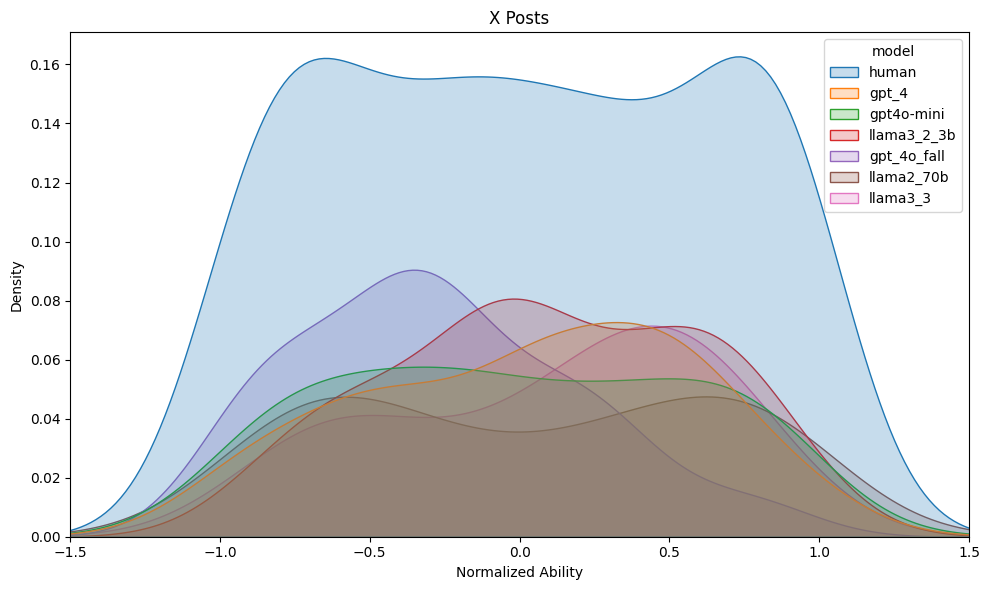


--- X Stats ---
             count      mean       std       min       max    median      mode
model                                                                         
gpt4o-mini      66 -0.013258  0.579440 -0.966216  0.929054 -0.050676 -0.966216
gpt_4           67  0.028489  0.539647 -0.996622  0.989865  0.104730 -0.996622
gpt_4o_fall     67 -0.273044  0.463486 -0.993243  0.841216 -0.324324 -0.993243
human          203  0.016043  0.624812 -1.000000  1.000000  0.016892 -1.000000
llama2_70b      56  0.029440  0.629935 -0.952703  0.983108  0.059122 -0.952703
llama3_2_3b     74  0.087199  0.510385 -0.925676  0.956081  0.060811 -0.925676
llama3_3        60  0.098367  0.538474 -0.976351  0.935811  0.228041 -0.976351


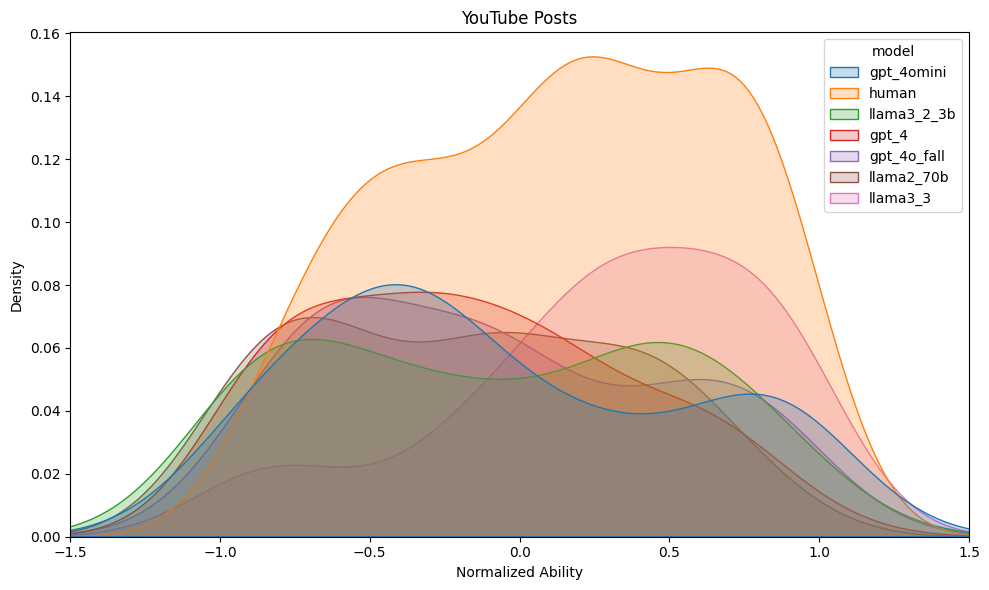


--- YouTube Stats ---
             count      mean       std       min       max    median      mode
model                                                                         
gpt_4           75 -0.172799  0.527590 -0.986644  0.996661 -0.228715 -0.986644
gpt_4o_fall     75 -0.076238  0.571761 -0.979967  0.976628 -0.135225 -0.979967
gpt_4omini      75 -0.072899  0.612296 -0.973289  0.993322 -0.242070 -0.973289
human          153  0.137582  0.532951 -0.923205  0.986644  0.185309 -0.923205
llama2_70b      73 -0.175704  0.543088 -0.996661  0.889816 -0.165275 -0.996661
llama3_2_3b     74 -0.081713  0.617979 -1.000000  0.983306 -0.078464 -1.000000
llama3_3        75  0.292910  0.528826 -0.989983  1.000000  0.388982 -0.989983


In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Utility function to plot KDE and print stats
def plot_and_describe(df, label):
    df['model'] = df['model'].fillna("human")

    # KDE plot
    plt.figure(figsize=(10, 6))
    sns.kdeplot(data=df, x="Normalized Ability", hue="model", fill=True)
    plt.title(f"{label} Posts")
    plt.xlabel("Normalized Ability")
    plt.ylabel("Density")
    plt.xlim(-1.5, 1.5)
    plt.tight_layout()
    plt.show()

    # Summary stats
    grouped = df.groupby('model')['Normalized Ability']
    stats_df = grouped.agg(['count', 'mean', 'std', 'min', 'max'])
    stats_df['median'] = grouped.median()
    stats_df['mode'] = grouped.apply(lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan)

    print(f"\n--- {label} Stats ---")
    print(stats_df)

# Load inverted X data
df_x = pd.read_csv("data/bt_x_posts_rankings_with_source_persona_inverted.csv")
plot_and_describe(df_x, label="X")

# Load inverted YT data
df_yt = pd.read_csv("data/bt_yt_posts_rankings_with_source_persona_inverted.csv")
plot_and_describe(df_yt, label="YouTube")


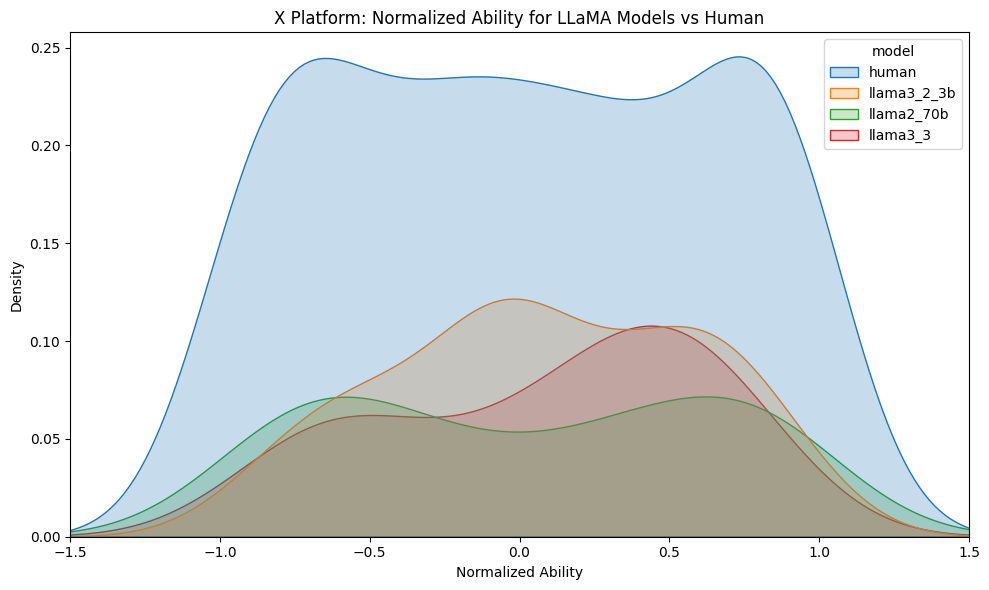

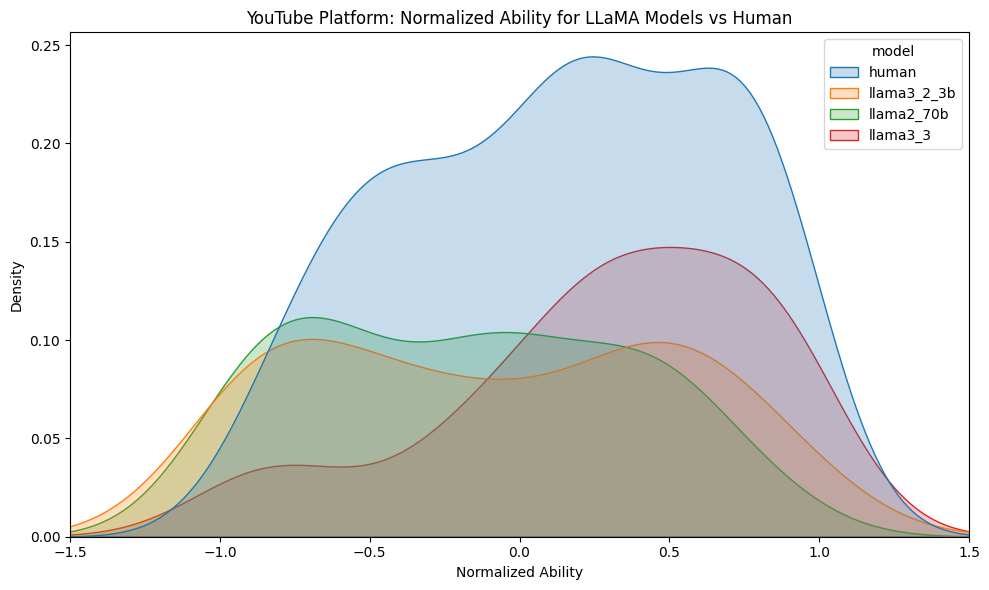

In [11]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def plot_llama_vs_human(df, label):
    df['model'] = df['model'].fillna("human")

    # Filter for LLaMA models or human
    df_filtered = df[
        df['model'].str.contains("llama", case=False, na=False) | 
        (df['model'] == "human")
    ]

    # Plot
    plt.figure(figsize=(10, 6))
    sns.kdeplot(data=df_filtered, x="Normalized Ability", hue="model", fill=True)
    plt.title(f"{label}: Normalized Ability for LLaMA Models vs Human")
    plt.xlabel("Normalized Ability")
    plt.ylabel("Density")
    plt.xlim(-1.5, 1.5)
    plt.tight_layout()
    plt.show()

# Load and plot for X platform
df_x = pd.read_csv("data/bt_x_posts_rankings_with_source_persona_inverted.csv")
plot_llama_vs_human(df_x, label="X Platform")

# Load and plot for YouTube platform
df_yt = pd.read_csv("data/bt_yt_posts_rankings_with_source_persona_inverted.csv")
plot_llama_vs_human(df_yt, label="YouTube Platform")


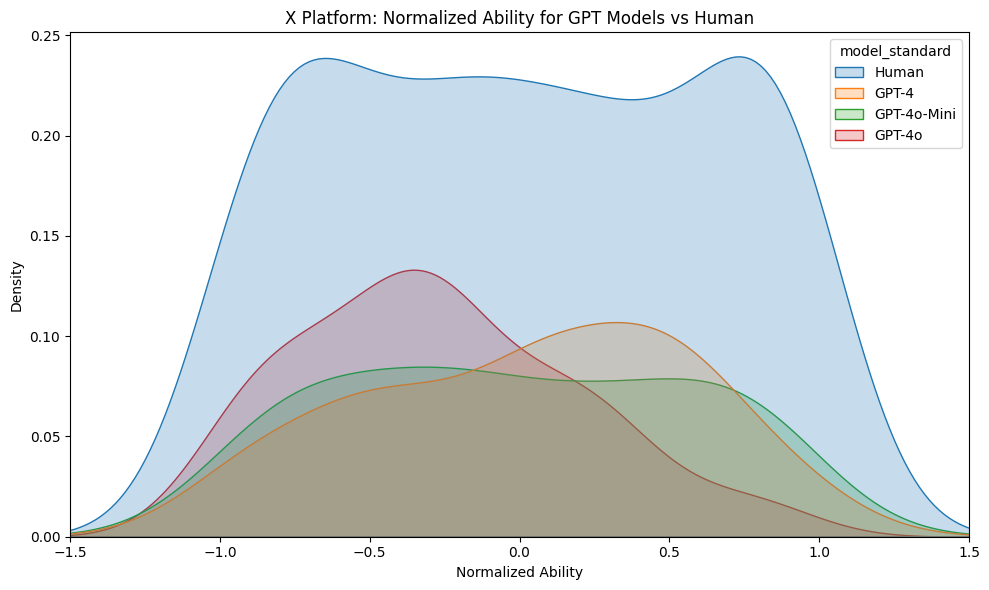

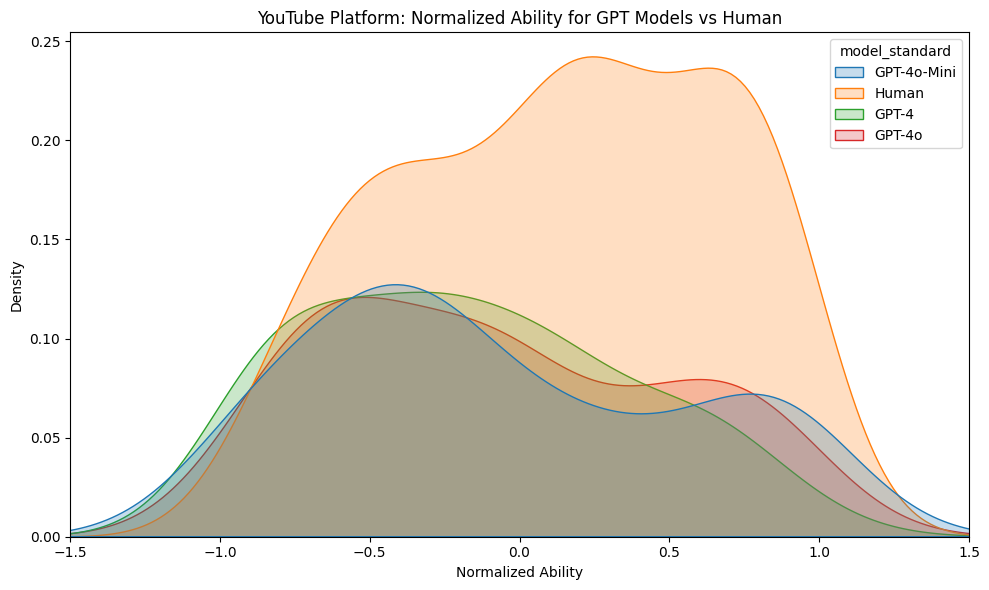

In [12]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Standardize model names
model_name_map = {
    "gpt_4": "GPT-4",
    "gpt_4o_fall": "GPT-4o",
    "gpt4o-mini": "GPT-4o-Mini",
    "gpt_4omini": "GPT-4o-Mini",
    "gpt4omini": "GPT-4o-Mini",
    "human": "Human"
}

target_models = ["GPT-4", "GPT-4o", "GPT-4o-Mini", "Human"]

def normalize_and_plot(df, label):
    df['model'] = df['model'].fillna("human").str.strip().str.lower()
    df['model_standard'] = df['model'].map(model_name_map)

    df_filtered = df[df['model_standard'].isin(target_models)]

    plt.figure(figsize=(10, 6))
    sns.kdeplot(data=df_filtered, x="Normalized Ability", hue="model_standard", fill=True)
    plt.title(f"{label}: Normalized Ability for GPT Models vs Human")
    plt.xlabel("Normalized Ability")
    plt.ylabel("Density")
    plt.xlim(-1.5, 1.5)
    plt.tight_layout()
    plt.show()

# X Platform
df_x = pd.read_csv("data/bt_x_posts_rankings_with_source_persona_inverted.csv")
normalize_and_plot(df_x, "X Platform")

# YouTube Platform
df_yt = pd.read_csv("data/bt_yt_posts_rankings_with_source_persona_inverted.csv")
normalize_and_plot(df_yt, "YouTube Platform")
